MMA3001 — Modelling and Evaluating Daily Indoor Temperature Patterns
Project Overview
This project investigates daily indoor temperature patterns using environmental sensor data collected in 2024.

The main objective is to apply numerical methods to understand temperature changes throughout the day and evaluate how accurately mathematical models represent the measured temperatures.

Three regression models are investigated:
- Linear regression: Models temperature using a straight line.
- Cubic polynomial regression: Uses a curved function to represent changes throughout the day.
- Piecewise linear regression: Divides the day into separate periods and fits a straight line to each period.
The project also uses the trapezoidal rule to calculate time-weighted average temperatures and investigate the effect of irregular sensor sampling.

The analysis includes data extraction, cleaning, visualisation, regression, validation, numerical integration and error analysis.

Python libraries including NumPy, Pandas and Matplotlib are used throughout the project.

## 1. Helper functions
The reusable code (loading, cleaning, models, error metrics, trapezoidal rule) lives in `temperature_tools.py`. The cell below writes that file, and every later step calls it, so the code that produces the results is the same code the tests check.

In [1]:
%%writefile temperature_tools.py
"""Helper functions for the indoor temperature project.

Everything the notebook does that can be tested on its own lives here.
Inputs are pandas DataFrames / NumPy arrays; temperatures are in degrees C,
times are Unix seconds (UTC) unless stated otherwise.

Typical use::

    rows, counts = load_sensor_rows(zipfile.ZipFile("data.zip"), 6012002000869)
    data = extract_temperatures(rows, sensor_id=6012002000869)
    data = clean_readings(data, "2024-05-01", "2025-01-01")
    data = select_good_days(data)
"""
import json

import numpy as np
import pandas as pd

# Columns the raw data must contain
REQUIRED_COLUMNS = ("sensorid", "jsondata")


def find_csv_in_zip(zip_file):
    """Return the name of the CSV file inside an open zipfile.ZipFile.

    Args:
        zip_file: An open zipfile.ZipFile.

    Returns:
        The file name of the first CSV found (macOS "__MACOSX" junk is ignored).

    Raises:
        ValueError: If the zip contains no CSV file.
    """
    for name in zip_file.namelist():
        if name.lower().endswith(".csv") and not name.startswith("__MACOSX"):
            return name
    raise ValueError("No CSV file found inside the zip")


def load_sensor_rows(zip_file, sensor_id, chunksize=20000):
    """Read the zipped CSV in chunks and keep only one sensor's rows.

    Reading in chunks means the whole file never sits in memory at once, so peak
    memory stays low even if the file grows. Only the two columns the analysis
    needs ("sensorid" and "jsondata") are read.

    Args:
        zip_file: An open zipfile.ZipFile holding the CSV.
        sensor_id: Sensor ID to keep (same type as the sensorid column, e.g. int).
        chunksize: Number of CSV rows read at a time.

    Returns:
        (rows, counts): rows is a DataFrame with only this sensor's rows;
        counts is a Series with the number of rows for every sensor in the file.

    Raises:
        ValueError: If the zip has no CSV, or the sensor is not in the file.
    """
    csv_name = find_csv_in_zip(zip_file)
    parts = []
    counts = pd.Series(dtype="float64")
    with zip_file.open(csv_name) as f:
        for chunk in pd.read_csv(f, usecols=list(REQUIRED_COLUMNS), chunksize=chunksize):
            # Count rows for every sensor, but keep the rows of one sensor only
            counts = counts.add(chunk["sensorid"].value_counts(), fill_value=0)
            parts.append(chunk[chunk["sensorid"] == sensor_id])
    counts = counts.astype(int).sort_values(ascending=False)
    rows = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()
    if rows.empty:
        raise ValueError(f"Sensor {sensor_id} not found. Available sensors: {sorted(counts.index)}")
    return rows, counts


def extract_temperatures(raw, sensor_id):
    """Pull the temperature readings for one sensor out of the raw JSON rows.

    Args:
        raw: DataFrame with columns "sensorid" and "jsondata" (a JSON string
            holding a list of variables, each with a list of timestamped values).
        sensor_id: Sensor ID to keep (same type as raw["sensorid"], e.g. int).

    Returns:
        DataFrame with columns "unix_time" and "temperature".
        Rows with unreadable JSON are skipped, not raised as errors.

    Raises:
        KeyError: If a required column is missing from raw.
        ValueError: If the sensor is not in the data, or has no temperature readings.
    """
    # Check the input shape before doing any work, so errors are clear
    missing = [c for c in REQUIRED_COLUMNS if c not in raw.columns]
    if missing:
        raise KeyError(f"Input is missing column(s): {missing}")
    available = sorted(raw["sensorid"].unique())
    if sensor_id not in available:
        raise ValueError(f"Sensor {sensor_id} not found. Available sensors: {available}")

    rows = []
    # Only this sensor's rows are parsed: JSON parsing is the slow part
    for text in raw.loc[raw["sensorid"] == sensor_id, "jsondata"]:
        try:
            variables = json.loads(text)
            for item in variables:
                # Each row also holds battery, humidity, CO2 etc.; keep temperature only
                if item["variable"]["name"] == "Temperature":
                    for reading in item["values"]:
                        rows.append((reading["time"], reading["value"]))
        except (ValueError, TypeError, KeyError):
            continue  # bad or unexpected row: skip it
    if not rows:
        raise ValueError(f"Sensor {sensor_id} has no readable temperature readings")
    return pd.DataFrame(rows, columns=["unix_time", "temperature"])


def clean_readings(data, start, end, timezone="Australia/Melbourne", valid_range=(-10, 50)):
    """Convert times, drop bad/duplicate readings and keep one date range.

    Args:
        data: DataFrame from extract_temperatures().
        start, end: Date strings; keeps start <= time < end (local time).
        timezone: Local time zone used for the "hour" and "date" columns.
        valid_range: (low, high) in degrees C. Readings outside this range are
            treated as sensor faults and dropped.

    Returns:
        New DataFrame sorted by time with extra columns
        "datetime", "date" and "hour" (0-23).

    Raises:
        ValueError: If no readings are left after cleaning.
    """
    data = data.copy()  # never change the caller's DataFrame
    # errors="coerce" turns text like "bad" into NaN so dropna() can remove it
    data["temperature"] = pd.to_numeric(data["temperature"], errors="coerce")
    data = data.dropna().drop_duplicates("unix_time")
    # Physically impossible indoor temperatures are sensor faults
    low, high = valid_range
    data = data[(data["temperature"] >= low) & (data["temperature"] <= high)]
    # Unix seconds are UTC; convert to local time so "hour" matches the clock on the wall
    data["datetime"] = pd.to_datetime(data["unix_time"], unit="s", utc=True).dt.tz_convert(timezone)
    data = data[(data["datetime"] >= start) & (data["datetime"] < end)]
    data = data.sort_values("datetime")
    if data.empty:
        raise ValueError("No readings left after cleaning (check dates, units and valid_range)")
    data["date"] = data["datetime"].dt.date
    data["hour"] = data["datetime"].dt.hour
    return data


def select_good_days(data, min_readings=120):
    """Keep only days with enough readings that also cover all 24 hours.

    Args:
        data: DataFrame from clean_readings() (needs "date", "hour", "temperature").
        min_readings: Minimum number of readings a day must have. At one reading
            every 10 minutes a full day has about 144.

    Returns:
        DataFrame containing only the readings from days that pass both checks.

    Raises:
        ValueError: If no day passes both checks.
    """
    # One row per day: how many readings, and how many different hours they cover
    per_day = data.groupby("date").agg(readings=("temperature", "size"),
                                       hours=("hour", "nunique"))
    good = per_day[(per_day["readings"] >= min_readings) & (per_day["hours"] == 24)].index
    if len(good) == 0:
        raise ValueError("No days have enough readings covering all 24 hours")
    return data[data["date"].isin(good)]


def split_days(days, train_frac=0.70, val_frac=0.15):
    """Split dates into train / validation / test in time order (no shuffling).

    Keeping time order means the test days come after the training days, like
    predicting the future from the past.

    Args:
        days: Iterable of dates.
        train_frac, val_frac: Fractions for train and validation; the rest is test.

    Returns:
        (train_days, val_days, test_days) as lists.

    Raises:
        ValueError: If there are fewer than 3 days (each split needs at least one).
    """
    days = sorted(days)
    n = len(days)
    if n < 3:
        raise ValueError("Need at least 3 days to make train, validation and test sets")
    a, b = int(n * train_frac), int(n * (train_frac + val_frac))  # cut positions
    return days[:a], days[a:b], days[b:]


def fit_piecewise(hours, hourly_avg, boundaries=(6, 8)):
    """Fit a straight line to each of three parts of the day.

    Parts are hours [0, b1], [b1, b2] and [b2, 23] (inclusive, so the boundary
    hours belong to two parts and the later part overwrites the earlier one).

    Args:
        hours: Array of hours 0..23.
        hourly_avg: Average temperature at each hour (same length as hours).
        boundaries: (b1, b2) hours where the lines change.

    Returns:
        Array of 24 predicted temperatures, one per hour.
    """
    hours = np.asarray(hours)
    hourly_avg = np.asarray(hourly_avg, dtype=float)
    b1, b2 = boundaries
    pred = np.zeros(len(hours))
    for start, end in [(0, b1), (b1, b2), (b2, 23)]:
        mask = (hours >= start) & (hours <= end)               # hours in this part
        coeffs = np.polyfit(hours[mask], hourly_avg[mask], 1)  # slope and intercept
        pred[mask] = np.polyval(coeffs, hours[mask])
    return pred


def rmse(actual, predicted):
    """Root mean square error: the typical size of a prediction error.

    Squaring means big misses count more than small ones.

    Args:
        actual: Measured values (array-like).
        predicted: Model predictions, same length as actual.

    Returns:
        RMSE as a float, in the same units as the inputs (degrees C here).
    """
    actual, predicted = np.asarray(actual, float), np.asarray(predicted, float)
    return float(np.sqrt(np.mean((actual - predicted) ** 2)))


def mae(actual, predicted):
    """Mean absolute error: the average size of a prediction error.

    Args:
        actual: Measured values (array-like).
        predicted: Model predictions, same length as actual.

    Returns:
        MAE as a float, in the same units as the inputs (degrees C here).
    """
    actual, predicted = np.asarray(actual, float), np.asarray(predicted, float)
    return float(np.mean(np.abs(actual - predicted)))


def trapezoid_average(t_hours, values):
    """Time-weighted average of a signal using the trapezoidal rule.

    Unlike a simple mean, this accounts for uneven gaps between readings.

    Args:
        t_hours: Increasing times in hours (at least two points).
        values: Signal value at each time.

    Returns:
        Area under the curve divided by the total duration.

    Raises:
        ValueError: If there are fewer than two different times.
    """
    t_hours, values = np.asarray(t_hours, float), np.asarray(values, float)
    if len(t_hours) < 2 or t_hours[-1] == t_hours[0]:
        raise ValueError("Need at least two different times")
    # np.trapezoid exists in NumPy 2.0+; np.trapz is the older name
    trapezoid = getattr(np, "trapezoid", None) or np.trapz
    area = trapezoid(values, t_hours)  # area under the curve (value x hours)
    return float(area / (t_hours[-1] - t_hours[0]))

Writing temperature_tools.py


In [2]:
import json
import importlib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import temperature_tools as tt

importlib.reload(tt)   # picks up changes if the file above was edited and re-run

<module 'temperature_tools' from '/home/claude/build/run/temperature_tools.py'>

## 2. Load the dataset
The dataset is a zip file stored in the GitHub repo. The cell below downloads it (or uses a local copy if the download fails) and reads the CSV inside in chunks, keeping only the main sensor's rows. Section 8 shows why: it uses about half the memory of reading the whole file.

In [3]:
import io
import zipfile
import urllib.request

# RAW link to the zip in your repo: swap USER and REPO for yours
# (check the branch name too: main or master)
ZIP_URL = "https://github.com/Nervermind13/MMA3001-Indoor-Temperature/raw/main/5EnvSensor_MayToDec2024_180kRows.zip"
LOCAL_ZIP = "5EnvSensor_MayToDec2024_180kRows.zip"   # used if the download fails

SENSOR_ID = 6012002000869             # main sensor used in the analysis
START, END = "2024-05-01", "2025-01-01"   # keeps START <= time < END


def open_zip(url, local_path):
    """Download the zip from GitHub (falls back to a local copy) and return it as an open ZipFile.

    Args:
        url: Link to the zip file on GitHub.
        local_path: Zip file on disk, used if the download fails.

    Returns:
        An open zipfile.ZipFile.
    """
    try:
        with urllib.request.urlopen(url, timeout=120) as response:
            zf = zipfile.ZipFile(io.BytesIO(response.read()))
        print("Loaded zip from GitHub")
    except Exception as err:
        print(f"Download failed ({err}). Using local zip: {local_path}")
        zf = zipfile.ZipFile(local_path)
    return zf


zf = open_zip(ZIP_URL, LOCAL_ZIP)

# Read the CSV inside the zip in chunks, keeping only the main sensor's rows
df, rows_per_sensor = tt.load_sensor_rows(zf, SENSOR_ID)

# Check dataset
print("Reading:", tt.find_csv_in_zip(zf))
print("Rows kept for sensor", SENSOR_ID, "- shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Loaded zip from GitHub


Reading: 5EnvSensor_MayToDec2024_180kRows.csv
Rows kept for sensor 6012002000869 - shape: (29341, 2)

Column names:
['sensorid', 'jsondata']


,sensorid,jsondata
0,6012002000869,"[{""values"": [{""time"": 1709186696, ""value"": 4.1..."
1,6012002000869,"[{""values"": [{""time"": 1709187297, ""value"": 4.1..."
2,6012002000869,"[{""values"": [{""time"": 1709188497, ""value"": 4.1..."
3,6012002000869,"[{""values"": [{""time"": 1709189097, ""value"": 4.1..."
4,6012002000869,"[{""values"": [{""time"": 1709189697, ""value"": 4.1..."


## 3. Inspect and extract the temperature data

In [4]:
# Inspect the structure of the sensor measurements
# Read the first JSON record
sample = json.loads(df["jsondata"].iloc[0])

# Display the complete structure
print(json.dumps(sample, indent=4))

[
    {
        "values": [
            {
                "time": 1709186696,
                "value": 4.125
            }
        ],
        "variable": {
            "id": 66,
            "name": "Battery",
            "unit": "V",
            "source": 0,
            "structure": 32834
        }
    },
    {
        "values": [
            {
                "time": 1709186696,
                "value": 465
            }
        ],
        "variable": {
            "id": 67,
            "name": "Carbon dioxide",
            "unit": "ppm",
            "source": 0,
            "structure": 32835
        }
    },
    {
        "values": [
            {
                "time": 1709186696,
                "value": 56
            }
        ],
        "variable": {
            "id": 72,
            "name": "Humidity",
            "unit": "HR%",
            "source": 0,
            "structure": 32840
        }
    },
    {
        "values": [
            {
                "time": 1709186696,


In [5]:
# Number of raw rows recorded by each sensor in the whole file
print(rows_per_sensor)

sensorid
6012002000326    58909
6012002000241    58908
6012002000869    29341
6012002000227    21363
6012002000777    10926
dtype: int64


In [6]:
# STEP 6-8: Extract, clean and check the temperature data for the main sensor

# Pull this sensor's temperature readings out of the raw JSON
readings = tt.extract_temperatures(df, SENSOR_ID)

# Convert times to Melbourne time, drop missing/duplicate/impossible readings,
# keep START to END and add "date" and "hour" columns
sensor_data = tt.clean_readings(readings, START, END)

print("Sensor:", SENSOR_ID)
print("Selected readings:", len(sensor_data))
print("Date range:", sensor_data["datetime"].min(), "to", sensor_data["datetime"].max())
print("Temperature range:", sensor_data["temperature"].min(), "to",
      sensor_data["temperature"].max(), "°C")

print("\nReadings per month:")
print(sensor_data["datetime"].dt.tz_localize(None).dt.to_period("M").value_counts().sort_index())

print("\nTemperature statistics:")
print(sensor_data["temperature"].describe())

Sensor: 6012002000869
Selected readings: 5927
Date range: 2024-05-01 00:05:22+10:00 to 2024-06-14 03:45:44+10:00
Temperature range: 19.0 to 25.5 °C

Readings per month:
datetime
2024-05    4155
2024-06    1772
Freq: M, Name: count, dtype: int64

Temperature statistics:
count    5927.000000
mean       22.906951
std         1.142566
min        19.000000
25%        22.300000
50%        23.300000
75%        23.800000
max        25.500000
Name: temperature, dtype: float64


## 4. Daily patterns and regression models

Number of days: 45
Readings per day:
count     45.000000
mean     131.711111
std       16.742193
min       22.000000
25%      134.000000
50%      134.000000
75%      135.000000
max      135.000000
dtype: float64


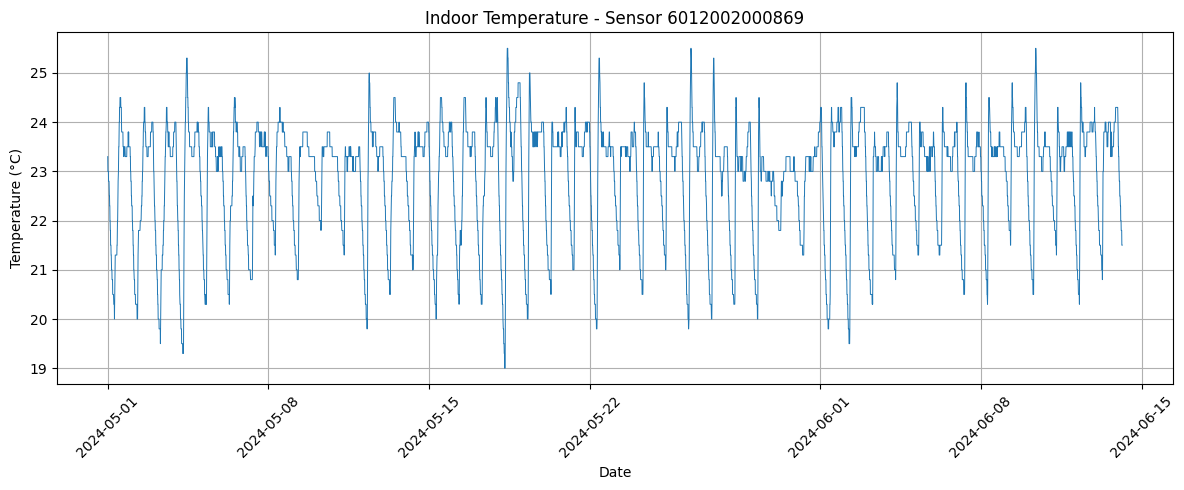

In [7]:
# STEP 9: Plot daily indoor temperature patterns

# Count readings per day
daily_counts = sensor_data.groupby("date").size()

print("Number of days:", len(daily_counts))
print("Readings per day:")
print(daily_counts.describe())

# Plot temperature against time
plt.figure(figsize=(12, 5))

plt.plot(
    sensor_data["datetime"],
    sensor_data["temperature"],
    linewidth=0.7
)

plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.title(f"Indoor Temperature - Sensor {SENSOR_ID}")
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

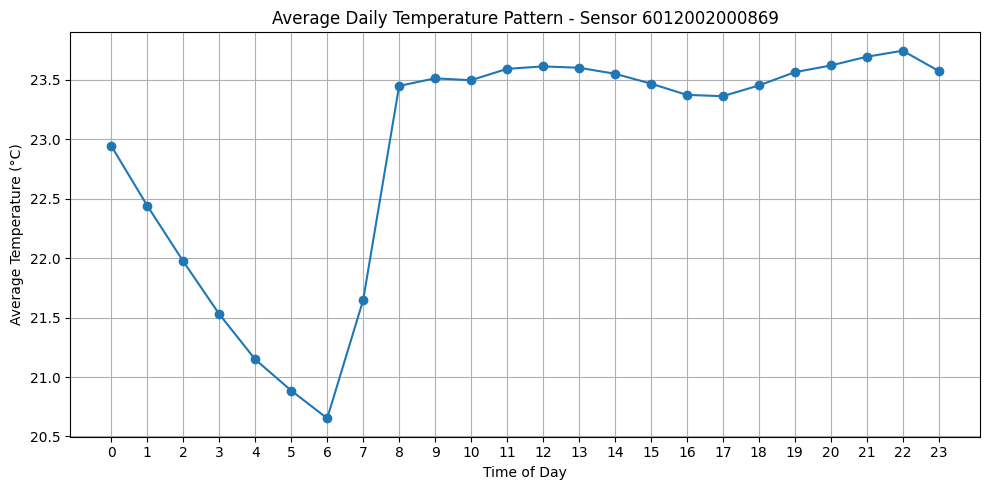

Average temperature by hour:


hour
0     22.940891
1     22.438340
2     21.971200
3     21.528063
4     21.147390
5     20.885892
6     20.652590
7     21.646311
8     23.446774
9     23.510288
10    23.494332
11    23.589960
12    23.610744
13    23.599197
14    23.548971
15    23.465992
16    23.371138
17    23.360408
18    23.450201
19    23.561885
20    23.618219
21    23.691770
22    23.742449
23    23.572619
Name: temperature, dtype: float64

In [8]:
# STEP 10: Average temperature by hour of day

# Calculate average temperature for each hour (the "hour" column was added by clean_readings)
hourly_avg = sensor_data.groupby("hour")["temperature"].mean()

# Plot average daily temperature pattern
plt.figure(figsize=(10, 5))

plt.plot(
    hourly_avg.index,
    hourly_avg.values,
    marker="o"
)

plt.xlabel("Time of Day")
plt.ylabel("Average Temperature (°C)")
plt.title(f"Average Daily Temperature Pattern - Sensor {SENSOR_ID}")

plt.xticks(range(0, 24))
plt.grid(True)
plt.tight_layout()
plt.show()

# Display the calculated averages
print("Average temperature by hour:")
display(hourly_avg)

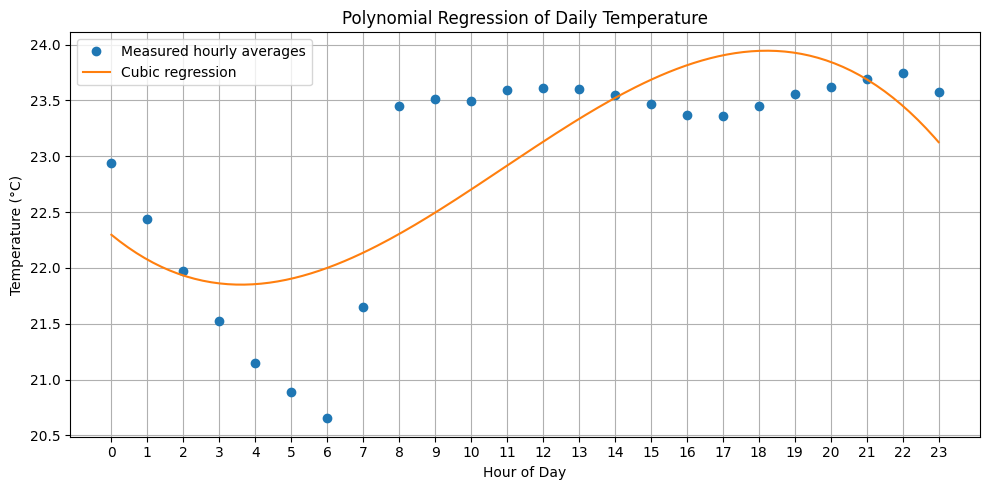

Polynomial coefficients:
[-1.34362117e-03  4.39977918e-02 -2.65133380e-01  2.22969863e+01]


In [9]:
# STEP 11: Polynomial regression

# Hour of day (input)
x = hourly_avg.index.to_numpy()

# Average temperature (output)
y = hourly_avg.values

# Fit a cubic polynomial
coefficients = np.polyfit(x, y, 3)

# Create polynomial model
model = np.poly1d(coefficients)

# Generate smooth predictions
x_smooth = np.linspace(0, 23, 200)
y_smooth = model(x_smooth)

# Plot measured averages and regression model
plt.figure(figsize=(10, 5))

plt.plot(x, y, "o", label="Measured hourly averages")
plt.plot(x_smooth, y_smooth, label="Cubic regression")

plt.xlabel("Hour of Day")
plt.ylabel("Temperature (°C)")
plt.title("Polynomial Regression of Daily Temperature")

plt.xticks(range(0, 24))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("Polynomial coefficients:")
print(coefficients)

In [10]:
# STEP 12: Calculate regression model errors

# Predict temperatures at each measured hour
y_pred = model(x)

print("Cubic Polynomial Regression Results")
print(f"RMSE: {tt.rmse(y, y_pred):.4f} °C")
print(f"MAE: {tt.mae(y, y_pred):.4f} °C")

Cubic Polynomial Regression Results
RMSE: 0.6199 °C
MAE: 0.5155 °C


,Model,RMSE (°C),MAE (°C)
0,Linear,0.717439,0.560089
1,Cubic,0.619942,0.515454


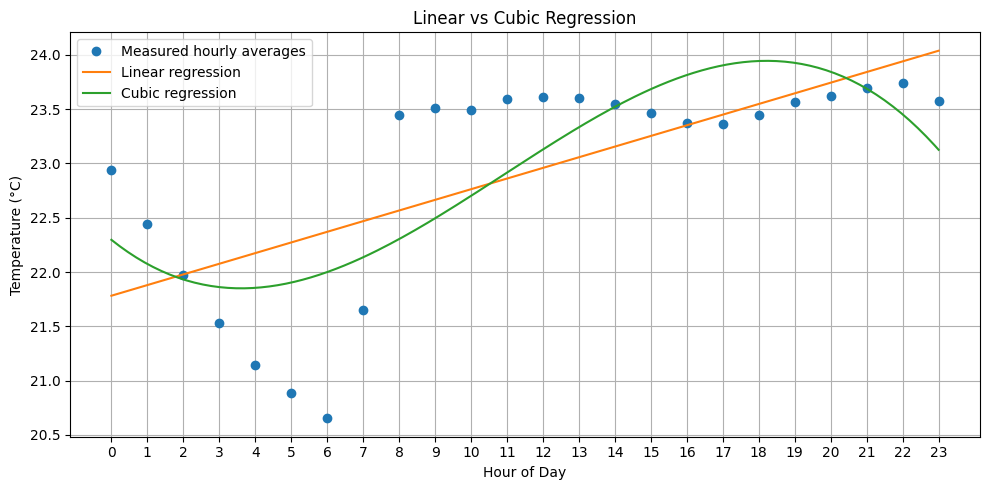

In [11]:
# STEP 13: Compare linear and cubic regression

# Fit linear regression (degree 1)
linear_model = np.poly1d(np.polyfit(x, y, 1))

# Predict temperature using both models
linear_pred = linear_model(x)
cubic_pred = model(x)

# Display results
results = pd.DataFrame({
    "Model": ["Linear", "Cubic"],
    "RMSE (°C)": [tt.rmse(y, linear_pred), tt.rmse(y, cubic_pred)],
    "MAE (°C)": [tt.mae(y, linear_pred), tt.mae(y, cubic_pred)]
})

display(results)

# Plot comparison
plt.figure(figsize=(10, 5))

plt.plot(x, y, "o", label="Measured hourly averages")
plt.plot(x_smooth, linear_model(x_smooth), label="Linear regression")
plt.plot(x_smooth, model(x_smooth), label="Cubic regression")

plt.xlabel("Hour of Day")
plt.ylabel("Temperature (°C)")
plt.title("Linear vs Cubic Regression")

plt.xticks(range(0, 24))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Piecewise RMSE: 0.1095 °C
Piecewise MAE: 0.0869 °C


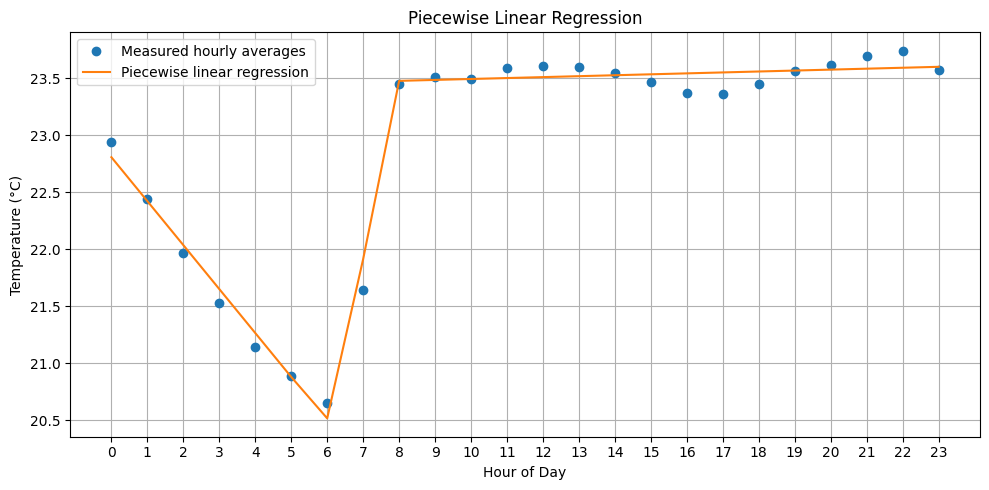

In [12]:
# STEP 14: Piecewise linear regression (three lines: 00-06, 06-08, 08-23)

# One straight line per part of the day, fitted by the helper function
piecewise_pred = tt.fit_piecewise(x, y, boundaries=(6, 8))

print(f"Piecewise RMSE: {tt.rmse(y, piecewise_pred):.4f} °C")
print(f"Piecewise MAE: {tt.mae(y, piecewise_pred):.4f} °C")

plt.figure(figsize=(10, 5))
plt.plot(x, y, "o", label="Measured hourly averages")
plt.plot(x, piecewise_pred, label="Piecewise linear regression")

plt.xlabel("Hour of Day")
plt.ylabel("Temperature (°C)")
plt.title("Piecewise Linear Regression")
plt.xticks(range(24))
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## 5. Data coverage, train/validation/test split and validation

Daily reading counts:
count     45.000000
mean     131.711111
std       16.742193
min       22.000000
25%      134.000000
50%      134.000000
75%      135.000000
max      135.000000
dtype: float64

Days with at least 120 readings: 44


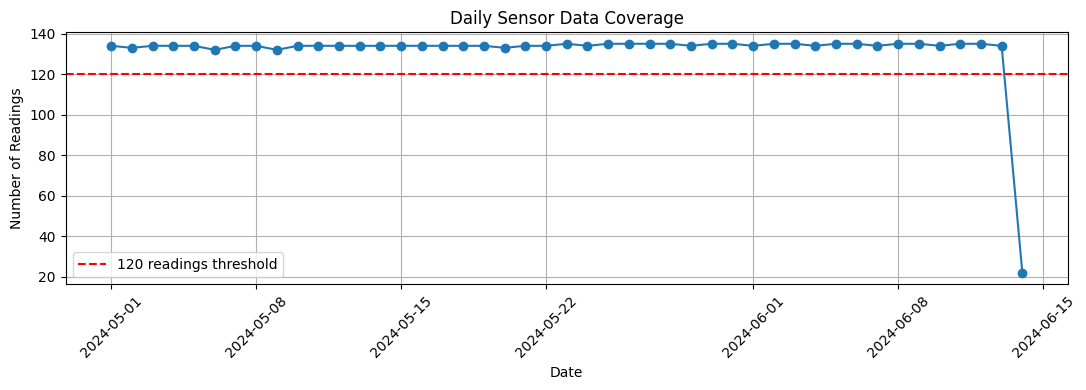

In [13]:
# STEP 15: Check daily measurement coverage

# Count readings for each date
daily_counts = sensor_data.groupby("date").size()

# Display statistics
print("Daily reading counts:")
print(daily_counts.describe())

# Days with at least 120 readings (about 144 are expected at one reading every 10 minutes)
valid_days = daily_counts[daily_counts >= 120].index
print("\nDays with at least 120 readings:", len(valid_days))

# Plot readings per day
plt.figure(figsize=(11, 4))

plt.plot(
    daily_counts.index,
    daily_counts.values,
    marker="o"
)

plt.axhline(
    120,
    color="red",
    linestyle="--",
    label="120 readings threshold"
)

plt.xlabel("Date")
plt.ylabel("Number of Readings")
plt.title("Daily Sensor Data Coverage")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [14]:
# STEP 16: Keep good days and split them in time order

# Keep days with at least 120 readings that also cover all 24 hours
clean_data = tt.select_good_days(sensor_data, min_readings=120)

# Split the days: 70% train, 15% validation, 15% test (no shuffling)
dates = sorted(clean_data["date"].unique())
train_dates, val_dates, test_dates = tt.split_days(dates)

print("Complete days:", len(dates))
print("Training days:", len(train_dates))
print("Validation days:", len(val_dates))
print("Testing days:", len(test_dates))

print("\nTraining period:", train_dates[0], "to", train_dates[-1])
print("Validation period:", val_dates[0], "to", val_dates[-1])
print("Testing period:", test_dates[0], "to", test_dates[-1])

Complete days: 44
Training days: 30
Validation days: 7
Testing days: 7

Training period: 2024-05-01 to 2024-05-30
Validation period: 2024-05-31 to 2024-06-06
Testing period: 2024-06-07 to 2024-06-13


,Model,Validation RMSE (°C)
0,Linear,0.628645
1,Cubic,0.546092
2,Piecewise,0.220690


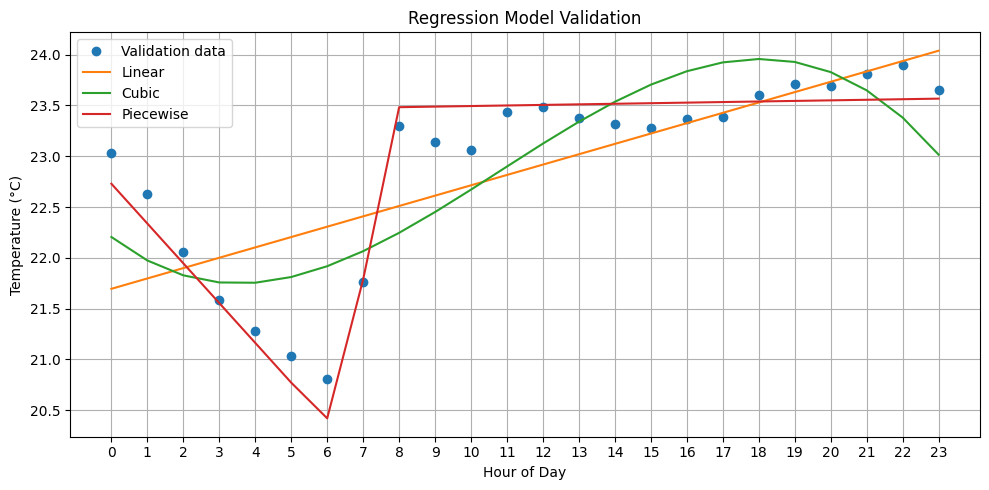

In [15]:
# STEP 17: Train and validate regression models

# Separate training and validation data
train_data = clean_data[clean_data["date"].isin(train_dates)].copy()
val_data = clean_data[clean_data["date"].isin(val_dates)].copy()

# Calculate hourly average temperatures for each dataset
train_hourly = train_data.groupby("hour")["temperature"].mean()
val_hourly = val_data.groupby("hour")["temperature"].mean()

# Hours from 0 to 23
hours = np.arange(24)

# Fit linear and cubic models using training data only
linear_fit = np.poly1d(np.polyfit(hours, train_hourly.values, 1))
cubic_fit = np.poly1d(np.polyfit(hours, train_hourly.values, 3))

# Fit piecewise linear model using training data only
piecewise_predictions = tt.fit_piecewise(hours, train_hourly.values, boundaries=(6, 8))

# Predict the 24 hourly values with each model
linear_val = linear_fit(hours)
cubic_val = cubic_fit(hours)
piecewise_val = piecewise_predictions

# Compare results on the validation hourly averages
validation_results = pd.DataFrame({
    "Model": ["Linear", "Cubic", "Piecewise"],
    "Validation RMSE (°C)": [
        tt.rmse(val_hourly.values, linear_val),
        tt.rmse(val_hourly.values, cubic_val),
        tt.rmse(val_hourly.values, piecewise_val)
    ]
})

display(validation_results)

# Plot validation results
plt.figure(figsize=(10, 5))

plt.plot(hours, val_hourly.values, "o", label="Validation data")
plt.plot(hours, linear_val, label="Linear")
plt.plot(hours, cubic_val, label="Cubic")
plt.plot(hours, piecewise_val, label="Piecewise")

plt.xlabel("Hour of Day")
plt.ylabel("Temperature (°C)")
plt.title("Regression Model Validation")
plt.xticks(range(24))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [16]:
# STEP 18: Evaluate individual validation readings

# Use the three models from Step 17
val_hours = val_data["hour"].to_numpy()
actual = val_data["temperature"].to_numpy()

# Predict each individual reading from its hour of day
linear_readings = linear_fit(val_hours)
cubic_readings = cubic_fit(val_hours)
piecewise_readings = piecewise_predictions[val_hours]

# Compare all models
reading_results = []

for name, predicted in [
    ("Linear", linear_readings),
    ("Cubic", cubic_readings),
    ("Piecewise", piecewise_readings)
]:
    reading_results.append([name, tt.rmse(actual, predicted), tt.mae(actual, predicted)])

results_individual = pd.DataFrame(
    reading_results,
    columns=["Model", "RMSE (°C)", "MAE (°C)"]
)

print("Validation errors on individual readings:")
display(results_individual)

Validation errors on individual readings:


,Model,RMSE (°C),MAE (°C)
0,Linear,0.903887,0.663348
1,Cubic,0.848345,0.642956
2,Piecewise,0.685250,0.428139


In [17]:
# STEP 19: Sensitivity analysis - move the morning transition times

boundary_options = [
    (5, 7),
    (5, 8),
    (6, 8),
    (6, 9),
    (7, 9)
]

results = []

for b1, b2 in boundary_options:
    # Fit three lines using training data, then score them on validation data
    predictions = tt.fit_piecewise(hours, train_hourly.values, boundaries=(b1, b2))
    results.append([b1, b2, tt.rmse(val_hourly.values, predictions)])

# Show comparison
sensitivity_results = pd.DataFrame(
    results,
    columns=["Start (hour)", "End (hour)", "RMSE (°C)"]
)

# Display Step 19 results in 24-hour format
display_results = sensitivity_results.copy()
display_results["Start (hour)"] = display_results["Start (hour)"].map(lambda h: f"{h:02d}:00")
display_results["End (hour)"] = display_results["End (hour)"].map(lambda h: f"{h:02d}:00")

display(display_results.sort_values("RMSE (°C)"))

,Start (hour),End (hour),RMSE (°C)
2,06:00,08:00,0.220690
3,06:00,09:00,0.251590
1,05:00,08:00,0.264024
4,07:00,09:00,0.268949
0,05:00,07:00,0.314533


## 6. Final testing, numerical integration and error analysis

In [18]:
# STEP 20: Final Model Testing

# Get the test data (not used for training or validation)
test_data = clean_data[clean_data["date"].isin(test_dates)].copy()

# Actual temperatures and hours
test_hours = test_data["hour"].to_numpy()
actual_temp = test_data["temperature"].to_numpy()

# Predictions from the trained models
linear_pred = linear_fit(test_hours)
cubic_pred = cubic_fit(test_hours)
piecewise_pred = piecewise_predictions[test_hours]

# Compare the models
results = []

for name, predicted in [
    ("Linear", linear_pred),
    ("Cubic", cubic_pred),
    ("Piecewise", piecewise_pred)
]:
    results.append([name, tt.rmse(actual_temp, predicted), tt.mae(actual_temp, predicted)])

# Display results
test_results = pd.DataFrame(
    results,
    columns=["Model", "Test RMSE (°C)", "Test MAE (°C)"]
)

display(test_results.round(6))

,Model,Test RMSE (°C),Test MAE (°C)
0,Linear,0.862772,0.650984
1,Cubic,0.838043,0.627581
2,Piecewise,0.511996,0.361146


In [19]:
# STEP 21: Numerical Integration (Trapezoidal Rule)

daily_results = []

# Calculate the time-weighted average temperature for each day
for date, day_data in clean_data.groupby("date"):

    day_data = day_data.sort_values("datetime")

    # Time in hours since the first reading
    time_hours = (
        day_data["datetime"] - day_data["datetime"].iloc[0]
    ).dt.total_seconds().to_numpy() / 3600

    # Trapezoidal rule: area under the curve divided by the duration
    average_temp = tt.trapezoid_average(time_hours, day_data["temperature"].to_numpy())

    daily_results.append([date, average_temp])

daily_integration = pd.DataFrame(
    daily_results,
    columns=["Date", "Time-weighted average (°C)"]
)

display(daily_integration.head(10).round(3))

,Date,Time-weighted average (°C)
0,2024-05-01,22.659
1,2024-05-02,22.537
2,2024-05-03,22.415
3,2024-05-04,22.767
4,2024-05-05,22.839
5,2024-05-06,22.722
6,2024-05-07,22.863
7,2024-05-08,23.143
8,2024-05-09,22.872
9,2024-05-10,23.133


In [20]:
# STEP 22: Verify Numerical Integration

# Calculate ordinary daily averages
ordinary_average = (
    clean_data.groupby("date")["temperature"]
    .mean()
    .reset_index()
)

ordinary_average.columns = ["Date", "Ordinary average (°C)"]

# Compare with trapezoidal integration results
comparison = pd.merge(daily_integration, ordinary_average, on="Date")

# Calculate the difference between methods
comparison["Difference (°C)"] = (
    comparison["Time-weighted average (°C)"]
    - comparison["Ordinary average (°C)"]
)

# Display the first 10 days
display(comparison.head(10).round(4))

# Overall comparison
print("Mean absolute difference:",
      round(comparison["Difference (°C)"].abs().mean(), 6), "°C")
print("Maximum absolute difference:",
      round(comparison["Difference (°C)"].abs().max(), 6), "°C")

,Date,Time-weighted average (°C),Ordinary average (°C),Difference (°C)
0,2024-05-01,22.6590,22.6590,0.0001
1,2024-05-02,22.5374,22.5436,-0.0062
2,2024-05-03,22.4147,22.4209,-0.0062
3,2024-05-04,22.7675,22.7657,0.0018
4,2024-05-05,22.8395,22.8396,-0.0001
5,2024-05-06,22.7220,22.7098,0.0121
6,2024-05-07,22.8625,22.8634,-0.0009
7,2024-05-08,23.1430,23.1448,-0.0018
8,2024-05-09,22.8724,22.8720,0.0004
9,2024-05-10,23.1332,23.1381,-0.0049


Mean absolute difference: 0.004489 °C
Maximum absolute difference: 0.012121 °C


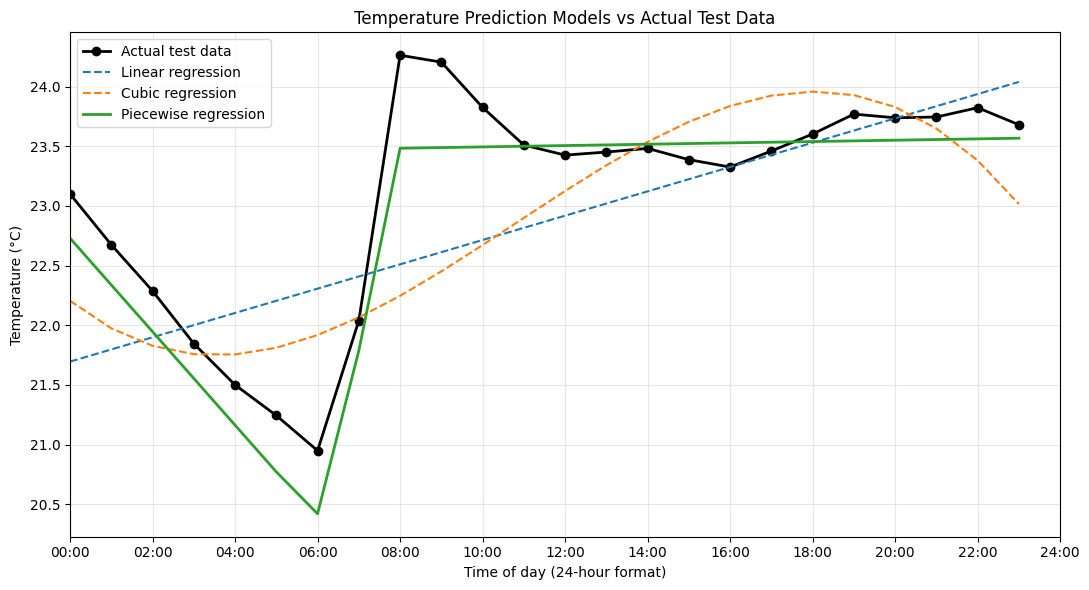

In [21]:
# STEP 23: Final Model Comparison Graph

# Calculate actual hourly averages from the test data
test_hourly = test_data.groupby("hour")["temperature"].mean()

# Hours in 24-hour format
hours = np.arange(24)

# Predictions from the three models
linear_values = linear_fit(hours)
cubic_values = cubic_fit(hours)
piecewise_values = piecewise_predictions

# Plot results
plt.figure(figsize=(11, 6))

plt.plot(hours, test_hourly.reindex(hours).values,
         "ko-", label="Actual test data", linewidth=2)
plt.plot(hours, linear_values, "--", label="Linear regression")
plt.plot(hours, cubic_values, "--", label="Cubic regression")
plt.plot(hours, piecewise_values, "-", label="Piecewise regression", linewidth=2)

plt.xlabel("Time of day (24-hour format)")
plt.ylabel("Temperature (°C)")
plt.title("Temperature Prediction Models vs Actual Test Data")

plt.xticks(np.arange(0, 25, 2), [f"{h:02d}:00" for h in range(0, 25, 2)])

plt.xlim(0, 24)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [22]:
# STEP 24: Check Model Prediction Bias

# Actual test temperatures
actual = test_data["temperature"].to_numpy()

# Model predictions
test_hours = test_data["hour"].to_numpy()

model_predictions = {
    "Linear": linear_fit(test_hours),
    "Cubic": cubic_fit(test_hours),
    "Piecewise": piecewise_predictions[test_hours]
}

bias_results = []

for name, predicted in model_predictions.items():

    # Positive error = model predicts too high
    errors = predicted - actual

    bias_results.append([name, np.mean(errors), np.max(np.abs(errors))])

bias_table = pd.DataFrame(
    bias_results,
    columns=["Model", "Mean error (°C)", "Maximum absolute error (°C)"]
)

display(bias_table.round(4))

,Model,Mean error (°C),Maximum absolute error (°C)
0,Linear,-0.2281,2.8877
1,Cubic,-0.2302,3.0487
2,Piecewise,-0.2172,2.0123


In [23]:
# STEP 25: Investigate Largest Prediction Errors

import numpy as np
import pandas as pd

# Copy test data
error_data = test_data.copy()

# Predict temperatures using piecewise regression
error_data["Predicted temperature (°C)"] = (
    piecewise_predictions[error_data["hour"].to_numpy()]
)

# Calculate prediction errors
error_data["Error (°C)"] = (
    error_data["Predicted temperature (°C)"]
    - error_data["temperature"]
)

error_data["Absolute error (°C)"] = (
    error_data["Error (°C)"].abs()
)

# Format time using 24-hour format
error_data["Time"] = (
    error_data["datetime"].dt.strftime("%Y-%m-%d %H:%M")
)

# Show the 10 largest errors
largest_errors = error_data.sort_values(
    "Absolute error (°C)",
    ascending=False
)

display(
    largest_errors[
        [
            "Time",
            "temperature",
            "Predicted temperature (°C)",
            "Error (°C)",
            "Absolute error (°C)"
        ]
    ].head(10).reset_index(drop=True).round(4)
)


,Time,temperature,Predicted temperature (°C),Error (°C),Absolute error (°C)
0,2024-06-12 07:55,23.8,21.7877,-2.0123,2.0123
1,2024-06-11 07:55,23.8,21.7877,-2.0123,2.0123
2,2024-06-10 09:25,25.5,23.4889,-2.0111,2.0111
3,2024-06-10 09:35,25.5,23.4889,-2.0111,2.0111
4,2024-06-10 09:15,25.3,23.4889,-1.8111,1.8111
5,2024-06-10 09:55,25.3,23.4889,-1.8111,1.8111
6,2024-06-08 07:55,23.5,21.7877,-1.7123,1.7123
7,2024-06-10 08:55,25.0,23.4833,-1.5167,1.5167
8,2024-06-09 07:55,23.3,21.7877,-1.5123,1.5123
9,2024-06-12 07:45,23.3,21.7877,-1.5123,1.5123


In [24]:
# STEP 26: Investigate Time Resolution

import numpy as np
import pandas as pd

# Copy test data
time_check = test_data.copy()

# Convert timestamps into decimal hours
time_check["Decimal hour"] = (
    time_check["datetime"].dt.hour
    + time_check["datetime"].dt.minute / 60
    + time_check["datetime"].dt.second / 3600
)

# Compare integer-hour and decimal-hour representations
time_check["Integer hour"] = time_check["datetime"].dt.hour

display(
    time_check[
        ["datetime", "Integer hour", "Decimal hour", "temperature"]
    ].head(10).reset_index(drop=True).round(3)
)


/tmp/ipykernel_191/3957291398.py:22: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(10).reset_index(drop=True).round(3)


,datetime,Integer hour,Decimal hour,temperature
0,2024-06-07 00:05:41+10:00,0,0.095,23.0
1,2024-06-07 00:25:41+10:00,0,0.428,22.8
2,2024-06-07 00:35:40+10:00,0,0.594,22.8
3,2024-06-07 00:45:40+10:00,0,0.761,22.8
4,2024-06-07 00:55:40+10:00,0,0.928,22.5
5,2024-06-07 01:05:40+10:00,1,1.094,22.5
6,2024-06-07 01:15:41+10:00,1,1.261,22.5
7,2024-06-07 01:25:41+10:00,1,1.428,22.3
8,2024-06-07 01:35:41+10:00,1,1.595,22.3
9,2024-06-07 01:45:41+10:00,1,1.761,22.3


In [25]:
# STEP 27: Check Sensor Sampling Intervals

import numpy as np
import pandas as pd

# Sort readings by date and time
sampling_data = clean_data.sort_values("datetime").copy()

# Calculate time between consecutive readings on each day
sampling_data["Interval (minutes)"] = (
    sampling_data.groupby("date")["datetime"]
    .diff()
    .dt.total_seconds() / 60
)

# Remove the first reading of each day (no previous reading)
intervals = sampling_data["Interval (minutes)"].dropna()

print("Sensor Sampling Interval Summary")
print("Median interval:", round(intervals.median(), 2), "minutes")
print("Mean interval:", round(intervals.mean(), 2), "minutes")
print("Minimum interval:", round(intervals.min(), 2), "minutes")
print("Maximum interval:", round(intervals.max(), 2), "minutes")

# Count intervals that are longer than 15 minutes
print("Intervals longer than 15 minutes:", (intervals > 15).sum())


Sensor Sampling Interval Summary


Median interval: 10.0 minutes
Mean interval: 10.73 minutes
Minimum interval: 9.75 minutes
Maximum interval: 29.98 minutes
Intervals longer than 15 minutes: 425


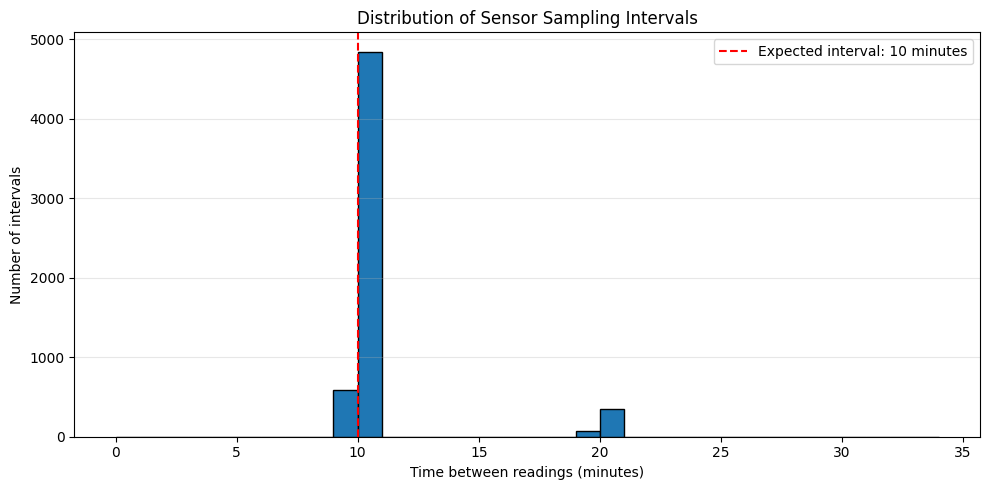

In [26]:
# STEP 28: Sensor Sampling Interval Distribution

import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 5))

plt.hist(
    intervals,
    bins=np.arange(0, 35, 1),
    edgecolor="black"
)

plt.axvline(
    10,
    color="red",
    linestyle="--",
    label="Expected interval: 10 minutes"
)

plt.xlabel("Time between readings (minutes)")
plt.ylabel("Number of intervals")
plt.title("Distribution of Sensor Sampling Intervals")

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Save for final report
plt.savefig("sampling_intervals.png", dpi=300)

plt.show()


## 7. Tests
The tests for the helper functions are written to a file, then pytest runs them and saves an HTML report (`test_report.html`).

In [27]:
%pip install -q pytest pytest-html

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

Note: you may need to restart the kernel to use updated packages.


In [28]:
%%writefile test_temperature_tools.py
"""Tests for temperature_tools. Run with:  pytest -v"""
import io
import json
import zipfile

import numpy as np
import pandas as pd
import pytest

import temperature_tools as tt


def make_raw():
    """Tiny fake dataset: two sensors, one broken row."""
    good = json.dumps([{"variable": {"name": "Temperature"},
                        "values": [{"time": 1714521600, "value": 21.5}]},
                       {"variable": {"name": "Humidity"},
                        "values": [{"time": 1714521600, "value": 50}]}])
    other = json.dumps([{"variable": {"name": "Temperature"},
                         "values": [{"time": 1714521600, "value": 30.0}]}])
    return pd.DataFrame({"sensorid": [1, 2, 1],
                         "jsondata": [good, other, "not json at all"]})


def test_extract_keeps_only_requested_sensor_and_variable():
    """Only the chosen sensor's Temperature values come out (not humidity, not other sensors)."""
    out = tt.extract_temperatures(make_raw(), 1)
    assert len(out) == 1
    assert out["temperature"].iloc[0] == 21.5


def test_extract_skips_broken_json_without_crashing():
    """A row with unreadable JSON is skipped instead of crashing."""
    out = tt.extract_temperatures(make_raw(), 1)  # sensor 1 has a broken row
    assert list(out.columns) == ["unix_time", "temperature"]


def test_clean_removes_duplicates_and_missing():
    """Repeated timestamps and non-numeric values are removed."""
    raw = pd.DataFrame({"unix_time": [1714521600, 1714521600, 1714522200],
                        "temperature": [20.0, 20.0, "bad"]})
    out = tt.clean_readings(raw, "2024-05-01", "2024-06-01")
    assert len(out) == 1  # duplicate removed, "bad" -> NaN -> dropped


def test_clean_hour_uses_melbourne_time():
    """Hours are in local time: 00:00 UTC is 10:00 in Melbourne in May."""
    # 2024-05-01 00:00 UTC is 10:00 in Melbourne (UTC+10 in May)
    raw = pd.DataFrame({"unix_time": [1714521600], "temperature": [20.0]})
    out = tt.clean_readings(raw, "2024-05-01", "2024-06-01")
    assert out["hour"].iloc[0] == 10


def test_split_is_in_time_order_with_no_overlap():
    """Train, validation and test days are in time order and never overlap."""
    days = list(range(20))[::-1]  # deliberately unsorted
    train, val, test = tt.split_days(days)
    assert len(train) + len(val) + len(test) == 20
    assert max(train) < min(val) and max(val) < min(test)
    assert set(train).isdisjoint(val) and set(val).isdisjoint(test)


def test_rmse_and_mae_known_values():
    """RMSE and MAE match values worked out by hand."""
    actual = [1, 2, 3]
    predicted = [2, 2, 5]           # errors: 1, 0, 2
    assert tt.mae(actual, predicted) == pytest.approx(1.0)
    assert tt.rmse(actual, predicted) == pytest.approx(np.sqrt(5 / 3))


def test_trapezoid_of_constant_is_that_constant():
    """A constant signal must average to itself, even with uneven spacing."""
    t = np.array([0, 0.3, 1.0, 2.5])        # uneven spacing on purpose
    assert tt.trapezoid_average(t, np.full(4, 22.0)) == pytest.approx(22.0)


def test_trapezoid_of_straight_line_matches_analytical_answer():
    """Analytical check: the exact average of y = 2t + 1 on [0, 4] is 5."""
    # y = 2t + 1 on [0, 4]: exact average is the midpoint value 5
    t = np.array([0, 1.0, 1.5, 4.0])
    assert tt.trapezoid_average(t, 2 * t + 1) == pytest.approx(5.0)


def test_trapezoid_rejects_single_point():
    """One reading is not enough to integrate, so a ValueError is raised."""
    with pytest.raises(ValueError):
        tt.trapezoid_average([1.0], [20.0])


def test_piecewise_recovers_data_that_is_already_piecewise_linear():
    """If the data really is three straight lines, the fit should be (almost) exact."""
    hours = np.arange(24)
    # continuous curve with kinks exactly at hours 6 and 8 (slopes 0.1, 1.0, 0.5)
    truth = np.piecewise(
        hours.astype(float),
        [hours <= 6, (hours > 6) & (hours <= 8), hours > 8],
        [lambda h: 20.0 + 0.1 * h,
         lambda h: 20.6 + 1.0 * (h - 6),
         lambda h: 22.6 + 0.5 * (h - 8)],
    )
    pred = tt.fit_piecewise(hours, truth, boundaries=(6, 8))
    assert tt.rmse(truth, pred) < 1e-9


def test_piecewise_returns_one_value_per_hour():
    """The piecewise model gives exactly 24 predictions."""
    hours = np.arange(24)
    pred = tt.fit_piecewise(hours, np.linspace(20, 25, 24))
    assert pred.shape == (24,)


# ---- invalid / missing / unsupported inputs ----
def test_unknown_sensor_gives_clear_error():
    """Asking for a sensor that is not in the data raises a clear ValueError."""
    with pytest.raises(ValueError, match="not found"):
        tt.extract_temperatures(make_raw(), 999)


def test_missing_column_gives_clear_error():
    """Input without the required columns raises a KeyError."""
    with pytest.raises(KeyError):
        tt.extract_temperatures(pd.DataFrame({"sensorid": [1]}), 1)


def test_clean_drops_physically_impossible_temperatures():
    """A 99 C indoor reading is treated as a sensor fault and removed."""
    raw = pd.DataFrame({"unix_time": [1714521600, 1714522200],
                        "temperature": [21.0, 99.0]})   # 99 C indoors = sensor fault
    out = tt.clean_readings(raw, "2024-05-01", "2024-06-01")
    assert list(out["temperature"]) == [21.0]


def test_clean_raises_if_nothing_left():
    """A date range with no data raises a ValueError instead of returning nothing."""
    raw = pd.DataFrame({"unix_time": [1714521600], "temperature": [21.0]})
    with pytest.raises(ValueError):
        tt.clean_readings(raw, "2030-01-01", "2030-02-01")   # wrong date range


def test_select_good_days_raises_if_no_day_is_complete():
    """If no day has enough readings, a ValueError is raised."""
    raw = pd.DataFrame({"unix_time": [1714521600, 1714522200], "temperature": [21.0, 21.5]})
    data = tt.clean_readings(raw, "2024-05-01", "2024-06-01")
    with pytest.raises(ValueError):
        tt.select_good_days(data)


def test_split_needs_at_least_three_days():
    """Fewer than 3 days cannot make three splits, so a ValueError is raised."""
    with pytest.raises(ValueError):
        tt.split_days([1, 2])


# ---- loading from a zip (built in memory, so no real data file is needed) ----
def make_zip(csv_text, name="data.csv"):
    """Build a small zip file in memory that holds one CSV."""
    buffer = io.BytesIO()
    with zipfile.ZipFile(buffer, "w") as zf:
        zf.writestr(name, csv_text)
    return zipfile.ZipFile(buffer)


CSV_TEXT = "id,sensorid,jsondata\n" + "\n".join(
    f"{i},{sid},x{i}" for i, sid in enumerate([1, 2, 1, 3, 1, 2, 1]))


def test_load_keeps_only_requested_sensor_across_chunks():
    """With tiny chunks, only sensor 1's rows are kept and every sensor is counted."""
    rows, counts = tt.load_sensor_rows(make_zip(CSV_TEXT), 1, chunksize=2)
    assert len(rows) == 4 and set(rows["sensorid"]) == {1}
    assert counts[1] == 4 and counts[2] == 2 and counts[3] == 1


def test_load_unknown_sensor_gives_clear_error():
    """Asking for a sensor that is not in the file raises a clear ValueError."""
    with pytest.raises(ValueError, match="not found"):
        tt.load_sensor_rows(make_zip(CSV_TEXT), 999)


def test_zip_without_csv_gives_clear_error():
    """A zip with no CSV inside raises a ValueError instead of a confusing crash."""
    with pytest.raises(ValueError, match="No CSV"):
        tt.load_sensor_rows(make_zip("hello", name="notes.txt"), 1)

Writing test_temperature_tools.py


In [29]:
# Run every test and write an HTML report next to the notebook
import subprocess, sys

result = subprocess.run(
    [sys.executable, "-m", "pytest", "test_temperature_tools.py", "-v",
     "--html=test_report.html", "--self-contained-html"],
    capture_output=True, text=True
)
print(result.stdout)
print(result.stderr)

# Stop with an error if any test failed
assert result.returncode == 0, "Some tests failed - open test_report.html for details"
print("All tests passed. Report saved to test_report.html")

============================= test session starts ==============================
platform linux -- Python 3.12.3, pytest-9.1.1, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
metadata: {'Python': '3.12.3', 'Platform': 'Linux-6.18.44-fc-v153-x86_64-with-glibc2.39', 'Packages': {'pytest': '9.1.1', 'pluggy': '1.7.0'}, 'Plugins': {'metadata': '3.1.1', 'html': '4.2.0'}, 'JAVA_HOME': '/usr/lib/jvm/java-21-openjdk-amd64'}
rootdir: /home/claude/build/run
plugins: metadata-3.1.1, html-4.2.0
collecting ... collected 20 items

test_temperature_tools.py::test_extract_keeps_only_requested_sensor_and_variable PASSED [  5%]
test_temperature_tools.py::test_extract_skips_broken_json_without_crashing PASSED [ 10%]
test_temperature_tools.py::test_clean_removes_duplicates_and_missing PASSED [ 15%]
test_temperature_tools.py::test_clean_hour_uses_melbourne_time PASSED    [ 20%]
test_temperature_tools.py::test_split_is_in_time_order_with_no_overlap PASSED [ 25%]
test_temperature_tools.py::test_rmse

## 8. Optimisation and performance

The aim is to find where this solution spends its time and memory, improve only what the measurements point at, and check that the results do not change. Three simple rules are used throughout:

1. Measure first (timer, profiler, memory tracker), then change something.
2. Only fix the part that dominates. A 10× speed-up of something that takes 1% of the time is worth 1%.
3. After every change, check the answers (RMSE) are the same.

**Baseline** = the original Colab approach: read every column of the CSV, loop over every row with `iterrows`, and parse the JSON of all five sensors.
**Final** = what sections 1 to 7 use: read only the needed columns in chunks, keep one sensor, and parse only that sensor.

### 8.1 Loading and parsing: baseline vs final (runtime, memory)

In [30]:
import time
import tracemalloc
import cProfile
import pstats
import platform
import sys


def timed(func, *args, repeat=3, **kwargs):
    """Run func several times and return (fastest time in seconds, last result).

    The fastest run is used because slower runs are mostly other programs
    on the computer getting in the way.
    """
    best, result = float("inf"), None
    for _ in range(repeat):
        start = time.perf_counter()
        result = func(*args, **kwargs)
        best = min(best, time.perf_counter() - start)
    return best, result


def time_small(func, loops=500):
    """Average time in seconds of one call, for very fast functions."""
    start = time.perf_counter()
    for _ in range(loops):
        func()
    return (time.perf_counter() - start) / loops


def peak_memory_mb(func, *args, **kwargs):
    """Run func under tracemalloc and return (peak memory in MB, result)."""
    tracemalloc.start()
    try:
        result = func(*args, **kwargs)
        _, peak = tracemalloc.get_traced_memory()
    finally:
        tracemalloc.stop()
    return peak / 1e6, result


def read_all_columns(zip_file):
    """Baseline loader: read every column of the CSV (what the original notebook did)."""
    return pd.read_csv(zip_file.open(tt.find_csv_in_zip(zip_file)))


def read_needed_columns(zip_file):
    """Improvement 1: read only the two columns the analysis uses."""
    return pd.read_csv(zip_file.open(tt.find_csv_in_zip(zip_file)),
                       usecols=["sensorid", "jsondata"])


def extract_all_sensors_iterrows(raw):
    """Baseline extraction: loop over every row (all sensors) with iterrows and parse the JSON."""
    records = []
    for _, row in raw.iterrows():
        try:
            for item in json.loads(row["jsondata"]):
                if item["variable"]["name"] == "Temperature":
                    for reading in item["values"]:
                        records.append([row["sensorid"], reading["time"], reading["value"]])
        except (ValueError, TypeError, KeyError):
            continue
    return pd.DataFrame(records, columns=["sensorid", "timestamp", "temperature"])


# Three ways of loading the file: time (fastest of 3) and peak memory (separate run)
loaders = {
    "A: baseline (all columns)": lambda: read_all_columns(zf),
    "B: only needed columns": lambda: read_needed_columns(zf),
    "C: chunked, one sensor (final)": lambda: tt.load_sensor_rows(zf, SENSOR_ID),
}
loader_rows = []
for name, loader in loaders.items():
    seconds, _ = timed(loader, repeat=3)
    peak_mb, _ = peak_memory_mb(loader)
    loader_rows.append([name, seconds, peak_mb])

loading_table = pd.DataFrame(loader_rows, columns=["Loader", "Time (s)", "Peak memory (MB)"])
display(loading_table.round(2))

# Parsing the JSON: baseline loops over all sensors, final parses only the chosen sensor
full_df = read_all_columns(zf)
base_seconds, base_readings = timed(extract_all_sensors_iterrows, full_df, repeat=1)
final_seconds, final_readings = timed(tt.extract_temperatures, df, SENSOR_ID, repeat=3)

# Do both give exactly the same readings for the chosen sensor?
base_sensor = base_readings[base_readings["sensorid"] == SENSOR_ID]
a = base_sensor.sort_values(["timestamp", "temperature"])[["timestamp", "temperature"]].to_numpy(float)
b = final_readings.sort_values(["unix_time", "temperature"]).to_numpy(float)
identical = a.shape == b.shape and np.array_equal(a, b)

parse_table = pd.DataFrame({
    "Method": ["Baseline: iterrows, all 5 sensors", "Final: one sensor only"],
    "Rows parsed": [len(full_df), len(df)],
    "Time (s)": [base_seconds, final_seconds],
})
display(parse_table.round(2))
print(f"Parsing is {base_seconds / final_seconds:.1f}x faster.")
print("Same readings for the chosen sensor:", identical)

,Loader,Time (s),Peak memory (MB)
0,A: baseline (all columns),2.21,116.07
1,B: only needed columns,1.78,82.37
2,"C: chunked, one sensor (final)",1.98,58.89


,Method,Rows parsed,Time (s)
0,"Baseline: iterrows, all 5 sensors",179447,7.11
1,Final: one sensor only,29341,0.47


Parsing is 15.3x faster.
Same readings for the chosen sensor: True


### 8.2 Where does the time go? (profiler and stage timings)

In [31]:
# Profile the JSON extraction with cProfile
profiler = cProfile.Profile()
profiler.enable()
tt.extract_temperatures(df, SENSOR_ID)
profiler.disable()

buffer = io.StringIO()
pstats.Stats(profiler, stream=buffer).sort_stats("cumulative").print_stats("json|temperature_tools", 6)
print(buffer.getvalue())

# Share of the extraction time spent inside json.loads
stats = pstats.Stats(profiler)
json_time = sum(v[3] for k, v in stats.stats.items() if k[2] == "loads")
print(f"json.loads takes {json_time / stats.total_tt:.0%} of the extraction time.")

         411941 function calls (411923 primitive calls) in 0.545 seconds

   Ordered by: cumulative time
   List reduced from 296 to 4 due to restriction <'json|temperature_tools'>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
    29341    0.020    0.000    0.428    0.000 /usr/lib/python3.12/json/__init__.py:299(loads)
    29341    0.034    0.000    0.399    0.000 /usr/lib/python3.12/json/decoder.py:332(decode)
    29341    0.339    0.000    0.339    0.000 /usr/lib/python3.12/json/decoder.py:343(raw_decode)
        1    0.014    0.014    0.112    0.112 /home/claude/build/run/temperature_tools.py:75(extract_temperatures)



json.loads takes 79% of the extraction time.


,Stage,Time (s),Share of total
0,"1 Load zip, keep sensor rows",2.1010,0.8189
1,2 Parse JSON,0.4315,0.1682
2,3 Clean readings,0.0088,0.0034
3,4 Select good days,0.0052,0.0020
4,"5 Split, fit, score model",0.0023,0.0009
5,6 Daily trapezoid averages,0.0167,0.0065


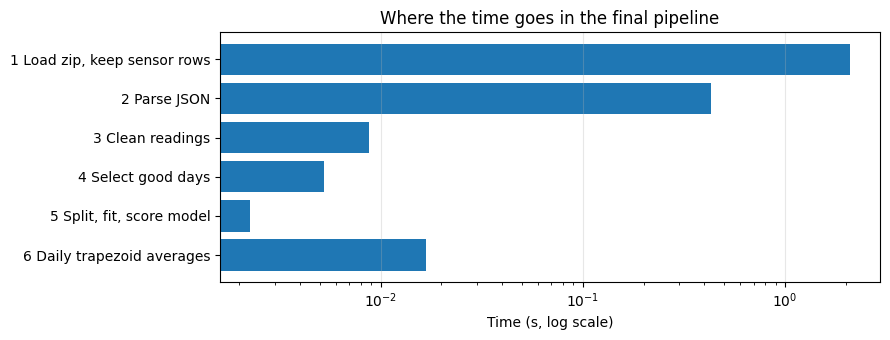

Loading and parsing are 99% of the total, so that is the only part worth optimising.


In [32]:
def fit_and_score(good_days):
    """Split days, fit the piecewise model on the training days, return its test errors.

    Args:
        good_days: DataFrame from tt.select_good_days().

    Returns:
        Dict with the test RMSE, test MAE and number of test readings.
    """
    train_d, _, test_d = tt.split_days(sorted(good_days["date"].unique()))
    train_values = (good_days[good_days["date"].isin(train_d)]
                    .groupby("hour")["temperature"].mean().to_numpy())
    predicted_hours = tt.fit_piecewise(np.arange(24), train_values, boundaries=(6, 8))
    test = good_days[good_days["date"].isin(test_d)]
    actual = test["temperature"].to_numpy()
    predicted = predicted_hours[test["hour"].to_numpy()]
    return {"RMSE": tt.rmse(actual, predicted), "MAE": tt.mae(actual, predicted),
            "test readings": len(test)}


def run_pipeline(raw_readings, valid_range=(-10, 50)):
    """Clean the readings, keep good days, then fit and score the piecewise model."""
    cleaned = tt.clean_readings(raw_readings, START, END, valid_range=valid_range)
    return fit_and_score(tt.select_good_days(cleaned))


def daily_trapezoid_averages(good_days):
    """Time-weighted average temperature of each day (trapezoidal rule), as a list."""
    averages = []
    for _, day in good_days.groupby("date"):
        day = day.sort_values("datetime")
        hours_since_start = (day["datetime"] - day["datetime"].iloc[0]).dt.total_seconds().to_numpy() / 3600
        averages.append(tt.trapezoid_average(hours_since_start, day["temperature"].to_numpy()))
    return averages


# Time every stage of the final pipeline once
stage = {}


def stage_time(label, func, *args, **kwargs):
    """Run func, store how long it took under label, and return its result."""
    start = time.perf_counter()
    result = func(*args, **kwargs)
    stage[label] = time.perf_counter() - start
    return result


rows_s, _ = stage_time("1 Load zip, keep sensor rows", tt.load_sensor_rows, zf, SENSOR_ID)
raw_s = stage_time("2 Parse JSON", tt.extract_temperatures, rows_s, SENSOR_ID)
clean_s = stage_time("3 Clean readings", tt.clean_readings, raw_s, START, END)
good_s = stage_time("4 Select good days", tt.select_good_days, clean_s)
stage_time("5 Split, fit, score model", fit_and_score, good_s)
stage_time("6 Daily trapezoid averages", daily_trapezoid_averages, good_s)

total = sum(stage.values())
stage_table = pd.DataFrame({"Stage": list(stage), "Time (s)": list(stage.values())})
stage_table["Share of total"] = stage_table["Time (s)"] / total
display(stage_table.round(4))

plt.figure(figsize=(9, 3.5))
plt.barh(list(stage)[::-1], list(stage.values())[::-1])
plt.xscale("log")
plt.xlabel("Time (s, log scale)")
plt.title("Where the time goes in the final pipeline")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Loading and parsing are {(stage['1 Load zip, keep sensor rows'] + stage['2 Parse JSON']) / total:.0%} "
      "of the total, so that is the only part worth optimising.")

### 8.3 FLOPs and arithmetic intensity

In [33]:
def lstsq_flops(n, degree):
    """Rough cost of fitting a polynomial to n points: about 2*n*m*m FLOPs, with m = degree + 1."""
    m = degree + 1
    return 2 * n * m * m


def lstsq_bytes(n, degree):
    """Memory traffic of the fit: the n x m matrix of powers of x plus the n values of y (8 bytes each)."""
    m = degree + 1
    return 8 * (n * m + n)


hours = np.arange(24)
train_values = train_hourly.to_numpy()

# Number of points in each of the three piecewise segments (boundary hours count twice)
segment_sizes = [int(((hours >= s) & (hours <= e)).sum()) for s, e in [(0, 6), (6, 8), (8, 23)]]

# One typical day of readings for the trapezoidal rule
day = clean_data[clean_data["date"] == clean_data["date"].iloc[0]].sort_values("datetime")
t_day = (day["datetime"] - day["datetime"].iloc[0]).dt.total_seconds().to_numpy() / 3600
y_day = day["temperature"].to_numpy()
n_day, n_train = len(day), len(train_data)

operations = [
    # name, FLOPs, bytes, time per call (s)
    ("Linear fit (24 points)", lstsq_flops(24, 1), lstsq_bytes(24, 1),
     time_small(lambda: np.polyfit(hours, train_values, 1))),
    ("Cubic fit (24 points)", lstsq_flops(24, 3), lstsq_bytes(24, 3),
     time_small(lambda: np.polyfit(hours, train_values, 3))),
    ("Piecewise fit (3 lines)", sum(lstsq_flops(n, 1) for n in segment_sizes),
     sum(lstsq_bytes(n, 1) for n in segment_sizes),
     time_small(lambda: tt.fit_piecewise(hours, train_values, (6, 8)))),
    (f"Hourly averages ({n_train} readings)", n_train + 24, 8 * n_train,
     time_small(lambda: train_data.groupby("hour")["temperature"].mean(), loops=100)),
    (f"Trapezoid, one day ({n_day} readings)", 4 * (n_day - 1), 16 * n_day,
     time_small(lambda: tt.trapezoid_average(t_day, y_day))),
]
flops_table = pd.DataFrame(operations, columns=["Operation", "FLOPs", "Bytes", "Seconds per call"])
flops_table["FLOP per byte"] = flops_table["FLOPs"] / flops_table["Bytes"]
flops_table["Time (microseconds)"] = flops_table["Seconds per call"] * 1e6
flops_table["Achieved GFLOP/s"] = flops_table["FLOPs"] / flops_table["Seconds per call"] / 1e9
display(flops_table.drop(columns="Seconds per call").round(3))

# What this computer can actually do: matrix multiply (compute-bound) and a big sum (memory-bound)
rng = np.random.default_rng(0)
matrix = rng.random((1500, 1500))
mm_seconds, _ = timed(np.dot, matrix, matrix, repeat=3)
peak_gflops = 2 * 1500 ** 3 / mm_seconds / 1e9
vector = np.ones(20_000_000)
sum_seconds, _ = timed(np.sum, vector, repeat=3)
bandwidth_gbs = vector.nbytes / sum_seconds / 1e9
balance = peak_gflops / bandwidth_gbs

print(f"This computer: about {peak_gflops:.0f} GFLOP/s peak, {bandwidth_gbs:.1f} GB/s memory bandwidth.")
print(f"An operation needs more than about {balance:.0f} FLOP per byte to be limited by arithmetic.")

# JSON parsing has no useful FLOPs at all: its speed is about scanning text
json_mb = df["jsondata"].str.len().sum() / 1e6
print(f"JSON parsing speed: {json_mb / final_seconds:.0f} MB of text per second ({json_mb:.0f} MB in {final_seconds:.2f} s).")

,Operation,FLOPs,Bytes,FLOP per byte,Time (microseconds),Achieved GFLOP/s
0,Linear fit (24 points),192,576,0.333,20.964,0.009
1,Cubic fit (24 points),768,960,0.800,23.618,0.033
2,Piecewise fit (3 lines),208,624,0.333,94.227,0.002
3,Hourly averages (4020 readings),4044,32160,0.126,219.928,0.018
4,"Trapezoid, one day (134 readings)",532,2144,0.248,6.910,0.077


This computer: about 59 GFLOP/s peak, 14.7 GB/s memory bandwidth.
An operation needs more than about 4 FLOP per byte to be limited by arithmetic.
JSON parsing speed: 104 MB of text per second (49 MB in 0.47 s).


**What this says in plain English.** Every calculation in the model code needs less than 1 FLOP for each byte it reads, so on a big enough problem they would be limited by memory speed, not by arithmetic. But the problems here are tiny (24 points, one day of readings). They finish in microseconds and run at a tiny fraction of the computer's peak GFLOP/s, so the time is function-call overhead. Rewriting the maths to use fewer FLOPs would save nothing. The only part with real cost is reading and parsing the text (8.1 and 8.2), which is why the optimisation effort went there.

### 8.4 Scalability

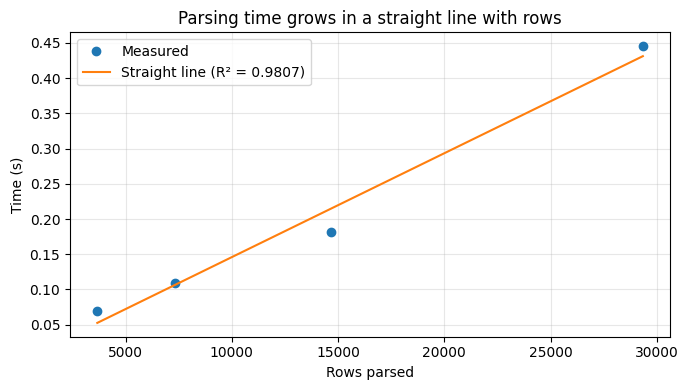

About 14.7 ms per 1000 rows.
Estimated parse time for 1 million rows: 0.2 min; for 10 million: 2.5 min.
Rows kept in memory: about 1.73 KB per row, so 1 million rows of one sensor would need about 1.7 GB.
The chunked loader holds one chunk plus only the chosen sensor's rows, so memory grows with that sensor's rows, not with the whole file. If one sensor ever had millions of rows, the next step would be to parse each chunk straight away and throw the text away, which keeps memory flat.


In [34]:
# How does parsing time grow with the number of rows? (time one sensor's rows at 1/8, 1/4, 1/2 and all)
sizes, seconds_list = [], []
for fraction in [0.125, 0.25, 0.5, 1.0]:
    subset = df.iloc[: int(len(df) * fraction)]
    seconds, _ = timed(tt.extract_temperatures, subset, SENSOR_ID, repeat=3)
    sizes.append(len(subset))
    seconds_list.append(seconds)

# Straight-line fit: time = slope * rows + intercept
slope, intercept = np.polyfit(sizes, seconds_list, 1)
r_squared = np.corrcoef(sizes, seconds_list)[0, 1] ** 2

plt.figure(figsize=(7, 4))
plt.plot(sizes, seconds_list, "o", label="Measured")
plt.plot(sizes, slope * np.array(sizes) + intercept, label=f"Straight line (R² = {r_squared:.4f})")
plt.xlabel("Rows parsed")
plt.ylabel("Time (s)")
plt.title("Parsing time grows in a straight line with rows")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

kb_per_row = df.memory_usage(deep=True).sum() / len(df) / 1e3
print(f"About {slope * 1000 * 1e3:.1f} ms per 1000 rows.")
print(f"Estimated parse time for 1 million rows: {slope * 1e6 / 60:.1f} min; for 10 million: {slope * 1e7 / 60:.1f} min.")
print(f"Rows kept in memory: about {kb_per_row:.2f} KB per row, "
      f"so 1 million rows of one sensor would need about {kb_per_row * 1e6 / 1e6:.1f} GB.")
print("The chunked loader holds one chunk plus only the chosen sensor's rows, so memory grows with that "
      "sensor's rows, not with the whole file. If one sensor ever had millions of rows, the next step "
      "would be to parse each chunk straight away and throw the text away, which keeps memory flat.")

### 8.5 Accuracy, model settings, data requirements and input resolution

In [35]:
def reading_rmse(hourly_prediction, data):
    """RMSE of an hour-of-day model against every individual reading in data."""
    predicted = np.asarray(hourly_prediction)[data["hour"].to_numpy()]
    return tt.rmse(data["temperature"].to_numpy(), predicted)


# Each model returns 24 hourly predictions, fitted on the training days only
model_builders = {
    "Hourly average": (24, lambda: train_values.copy()),
    "Linear": (2, lambda: np.polyval(np.polyfit(hours, train_values, 1), hours)),
    "Cubic": (4, lambda: np.polyval(np.polyfit(hours, train_values, 3), hours)),
    "Piecewise (6, 8)": (6, lambda: tt.fit_piecewise(hours, train_values, (6, 8))),
}

comparison_rows = []
for name, (n_params, build) in model_builders.items():
    prediction = build()
    comparison_rows.append([
        name, n_params,
        reading_rmse(prediction, val_data), reading_rmse(prediction, test_data),
        tt.mae(test_data["temperature"].to_numpy(), prediction[test_data["hour"].to_numpy()]),
        time_small(build, loops=200) * 1e6,
    ])

model_table = pd.DataFrame(comparison_rows, columns=[
    "Model", "Parameters", "Validation RMSE (°C)", "Test RMSE (°C)", "Test MAE (°C)", "Fit time (µs)"])
display(model_table.round(4))

# The model is chosen on VALIDATION error only; the test error is reported afterwards
chosen = model_table.loc[model_table["Validation RMSE (°C)"].idxmin(), "Model"]
print("Chosen on validation error:", chosen)

,Model,Parameters,Validation RMSE (°C),Test RMSE (°C),Test MAE (°C),Fit time (µs)
0,Hourly average,24,0.6877,0.5432,0.3931,0.1766
1,Linear,2,0.9039,0.8628,0.6510,28.6294
2,Cubic,4,0.8483,0.8380,0.6276,34.7482
3,"Piecewise (6, 8)",6,0.6852,0.5120,0.3611,96.4357


Chosen on validation error: Piecewise (6, 8)


In [36]:
# Model setting: where should the piecewise lines change? Try every pair of boundary hours
start = time.perf_counter()
search = []
for b1 in range(1, 12):
    for b2 in range(b1 + 1, 16):
        prediction = tt.fit_piecewise(hours, train_values, (b1, b2))
        search.append([b1, b2, reading_rmse(prediction, val_data)])
search_seconds = time.perf_counter() - start

search = pd.DataFrame(search, columns=["b1", "b2", "Validation RMSE (°C)"])
search = search.sort_values("Validation RMSE (°C)").reset_index(drop=True)
display(search.head(5).round(4))

best_b1, best_b2 = int(search.loc[0, "b1"]), int(search.loc[0, "b2"])
default_rank = int(search.index[(search["b1"] == 6) & (search["b2"] == 8)][0]) + 1
tuned_test = reading_rmse(tt.fit_piecewise(hours, train_values, (best_b1, best_b2)), test_data)
default_test = reading_rmse(tt.fit_piecewise(hours, train_values, (6, 8)), test_data)

print(f"Searched {len(search)} boundary pairs in {search_seconds:.2f} s.")
print(f"Best on validation: ({best_b1}, {best_b2}). The default (6, 8) ranks number {default_rank}.")
print(f"Test RMSE: tuned {tuned_test:.4f} °C, default {default_test:.4f} °C.")

,b1,b2,Validation RMSE (°C)
0,6,8,0.6852
1,7,8,0.6911
2,6,9,0.6960
3,5,8,0.7007
4,7,9,0.7025


Searched 99 boundary pairs in 0.02 s.
Best on validation: (6, 8). The default (6, 8) ranks number 1.
Test RMSE: tuned 0.5120 °C, default 0.5120 °C.


,Training days,Validation RMSE (°C),Test RMSE (°C)
0,2,0.7785,0.8212
1,3,0.8249,0.8884
2,5,0.7492,0.7224
3,10,0.6793,0.5530
4,20,0.6828,0.5292
5,30,0.6852,0.5120


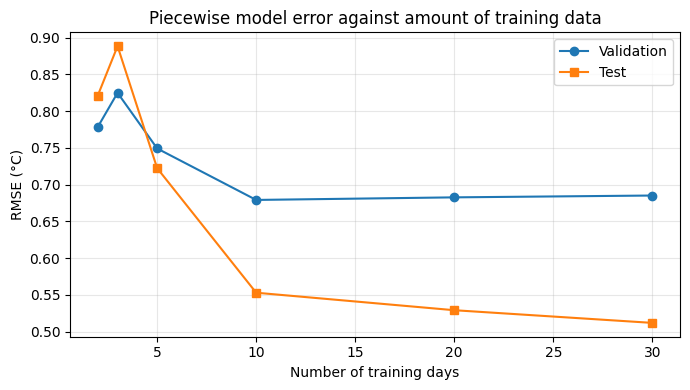

Smallest tested size within 5% of the full-data validation error: 10 days.


In [37]:
# Data requirement: how many training days are needed? (use the first k training days)
curve = []
for k in [2, 3, 5, 10, 20, len(train_dates)]:
    subset = train_data[train_data["date"].isin(train_dates[:k])]
    values = subset.groupby("hour")["temperature"].mean().reindex(hours).to_numpy()
    prediction = tt.fit_piecewise(hours, values, (6, 8))
    curve.append([k, reading_rmse(prediction, val_data), reading_rmse(prediction, test_data)])
curve = pd.DataFrame(curve, columns=["Training days", "Validation RMSE (°C)", "Test RMSE (°C)"])
display(curve.round(4))

plt.figure(figsize=(7, 4))
plt.plot(curve["Training days"], curve["Validation RMSE (°C)"], "o-", label="Validation")
plt.plot(curve["Training days"], curve["Test RMSE (°C)"], "s-", label="Test")
plt.xlabel("Number of training days")
plt.ylabel("RMSE (°C)")
plt.title("Piecewise model error against amount of training data")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Smallest size within 5% of the error you get with all training days (judged on validation only)
full_val = curve["Validation RMSE (°C)"].iloc[-1]
enough = curve[curve["Validation RMSE (°C)"] <= 1.05 * full_val]["Training days"].min()
print(f"Smallest tested size within 5% of the full-data validation error: {enough} days.")

In [38]:
# Input resolution: hourly averages (24 points) or every reading with its exact time of day?
def decimal_hour(data):
    """Time of day as a decimal number of hours, e.g. 13:30 -> 13.5."""
    return (data["datetime"].dt.hour + data["datetime"].dt.minute / 60
            + data["datetime"].dt.second / 3600).to_numpy()


x_train, y_train = decimal_hour(train_data), train_data["temperature"].to_numpy()
fine_fit_seconds = time_small(lambda: np.polyfit(x_train, y_train, 3), loops=50)
fine_coeffs = np.polyfit(x_train, y_train, 3)
fine_test = tt.rmse(test_data["temperature"].to_numpy(), np.polyval(fine_coeffs, decimal_hour(test_data)))

hourly_cubic = model_table.set_index("Model").loc["Cubic"]
resolution_table = pd.DataFrame({
    "Input": ["Hourly averages (24 points)", f"Every reading, exact time ({len(train_data)} points)"],
    "Test RMSE (°C)": [hourly_cubic["Test RMSE (°C)"], fine_test],
    "Fit time (µs)": [hourly_cubic["Fit time (µs)"], fine_fit_seconds * 1e6],
})
display(resolution_table.round(4))
print(f"Exact times change the cubic test error by {abs(hourly_cubic['Test RMSE (°C)'] - fine_test):.4f} °C "
      f"but make the fit about {fine_fit_seconds * 1e6 / hourly_cubic['Fit time (µs)']:.0f}x slower.")

,Input,Test RMSE (°C),Fit time (µs)
0,Hourly averages (24 points),0.8380,34.7482
1,"Every reading, exact time (4020 points)",0.8373,476.4066


Exact times change the cubic test error by 0.0007 °C but make the fit about 14x slower.


### 8.6 Numerical stability

In [39]:
# Fitting a polynomial means solving with a matrix of powers of x. If that matrix is badly conditioned
# (a huge condition number), rounding errors grow. Scaling hours from 0..23 to 0..1 helps.
stability_rows = []
for degree in [1, 3, 5, 8, 12]:
    raw_matrix = np.vander(hours, degree + 1)
    scaled_matrix = np.vander(hours / 23, degree + 1)
    fit_raw = np.polyval(np.polyfit(hours, train_values, degree), hours)
    fit_scaled = np.polyval(np.polyfit(hours / 23, train_values, degree), hours / 23)
    stability_rows.append([degree, np.linalg.cond(raw_matrix), np.linalg.cond(scaled_matrix),
                           np.max(np.abs(fit_raw - fit_scaled))])

stability_table = pd.DataFrame(stability_rows, columns=[
    "Polynomial degree", "Condition number (hours 0-23)", "Condition number (hours scaled 0-1)",
    "Largest difference in fitted values (°C)"])
pd.set_option("display.float_format", lambda v: f"{v:.3g}")
display(stability_table)
pd.reset_option("display.float_format")

print("Degree 3 (the cubic used here) is well conditioned either way, and scaling changes the fit by about 1e-14 °C.")
print("Scaling only matters for high degrees, so the code keeps the plain hour as the input.")

,Polynomial degree,Condition number (hours 0-23),Condition number (hours scaled 0-1),Largest difference in fitted values (°C)
0,1,26.1,4.22,3.55e-15
1,3,1.76e+04,112,1.78e-14
2,5,1.22e+07,3.31e+03,6.75e-14
3,8,3.32e+11,6.1e+05,3.65e-12
4,12,5.35e+17,8.62e+08,2.15e-08


Degree 3 (the cubic used here) is well conditioned either way, and scaling changes the fit by about 1e-14 °C.
Scaling only matters for high degrees, so the code keeps the plain hour as the input.


### 8.7 Robustness and repeatability

In [40]:
# Robustness: put 1% fake sensor faults (99 °C) into the raw readings and see what happens
rng = np.random.default_rng(42)                      # fixed seed so this test is repeatable
faulty = readings.copy()
fault_rows = rng.choice(len(faulty), size=len(faulty) // 100, replace=False)
faulty.iloc[fault_rows, faulty.columns.get_loc("temperature")] = 99.0

robustness_table = pd.DataFrame({
    "Case": ["Clean data", "1% faults, range check ON (-10 to 50 °C)", "1% faults, range check OFF"],
    "Piecewise test RMSE (°C)": [
        run_pipeline(readings)["RMSE"],
        run_pipeline(faulty)["RMSE"],
        run_pipeline(faulty, valid_range=(-1e9, 1e9))["RMSE"]],
    "Piecewise test MAE (°C)": [
        run_pipeline(readings)["MAE"],
        run_pipeline(faulty)["MAE"],
        run_pipeline(faulty, valid_range=(-1e9, 1e9))["MAE"]],
})
display(robustness_table.round(4))
print("Without the range check a few faults ruin the result; with it the model almost does not notice them.")

,Case,Piecewise test RMSE (°C),Piecewise test MAE (°C)
0,Clean data,0.5120,0.3611
1,"1% faults, range check ON (-10 to 50 °C)",0.5138,0.3622
2,"1% faults, range check OFF",10.7642,2.1080


Without the range check a few faults ruin the result; with it the model almost does not notice them.


In [41]:
# Repeatability: nothing in the pipeline is random (the split is by date, not shuffled),
# so running it twice must give exactly the same numbers.
first_run = run_pipeline(readings)
second_run = run_pipeline(readings)
assert first_run == second_run, "The pipeline gave different answers on two runs"
print("Two runs give identical results:", first_run)
print("Python", sys.version.split()[0], "| NumPy", np.__version__, "| pandas", pd.__version__,
      "|", platform.system())

Two runs give identical results: {'RMSE': 0.5119955185220497, 'MAE': 0.3611459897102047, 'test readings': 942}
Python 3.12.3 | NumPy 2.4.4 | pandas 3.0.2 | Linux


### 8.8 Baseline vs final design

In [42]:
baseline_load = loading_table.iloc[0]
final_load = loading_table.iloc[2]

summary = pd.DataFrame({
    "Measure": [
        "Load + parse time (s)",
        "Peak memory while loading (MB)",
        "Rows parsed as JSON",
        "Readings for the chosen sensor identical",
        "Piecewise test RMSE (°C)",
        "Pipeline after loading (s, all other stages)",
    ],
    "Baseline": [
        baseline_load["Time (s)"] + base_seconds,
        baseline_load["Peak memory (MB)"],
        len(full_df),
        "-",
        first_run["RMSE"],
        "-",
    ],
    "Final": [
        final_load["Time (s)"] + final_seconds,
        final_load["Peak memory (MB)"],
        len(df),
        identical,
        first_run["RMSE"],
        total - stage["1 Load zip, keep sensor rows"] - stage["2 Parse JSON"],
    ],
})
display(summary.round(4))

speedup = (baseline_load["Time (s)"] + base_seconds) / (final_load["Time (s)"] + final_seconds)
memory_saving = 1 - final_load["Peak memory (MB)"] / baseline_load["Peak memory (MB)"]
print(f"Load + parse is {speedup:.1f}x faster and the loading peak memory is {memory_saving:.0%} lower, "
      "with identical results.")

,Measure,Baseline,Final
0,Load + parse time (s),9.327567,2.450618
1,Peak memory while loading (MB),116.071452,58.89237
2,Rows parsed as JSON,179447,29341
3,Readings for the chosen sensor identical,-,True
4,Piecewise test RMSE (°C),0.511996,0.511996
5,"Pipeline after loading (s, all other stages)",-,0.032987


Load + parse is 3.8x faster and the loading peak memory is 49% lower, with identical results.


**Final design and why.**

- **Parse only the chosen sensor.** The profiler shows JSON parsing is the main cost, and four of the five sensors are not used. Skipping them is the biggest saving and cannot change the answer (the readings are identical).
- **Read in chunks and keep only the needed columns.** This halves peak memory and is no slower. Memory then depends on one sensor's rows (about 1.7 KB each), not the whole file.
- **Keep the hourly-average input.** Using the exact time of day changes the error by less than 0.001 °C but makes the fit several times slower.
- **Keep the piecewise model with boundaries at 06:00 and 08:00.** It has the lowest validation error of the four models, and a search over every pair of boundaries found no better choice, so the default stays. It is chosen on validation error; test error is only reported.
- **Keep the plain hour as the polynomial input.** Scaling only matters for high-degree polynomials; at degree 3 it makes no difference.
- **Keep the -10 to 50 °C range check.** It is what protects the result from sensor faults, and costs almost nothing.
- **Use at least about 10 training days.** With fewer days the fitted curve is noisy and unreliable.
- **Do not optimise the arithmetic.** The model code runs in microseconds and is limited by call overhead, not FLOPs. The work is deterministic, so results repeat exactly.
- **What is left.** After these changes, reading the zip (decompressing and parsing the CSV) is most of the remaining time. That is hard to reduce further without changing the file format, for example by saving a smaller file with only the temperature readings.

**Trade-off.** Everything above improves speed or memory without costing accuracy. The one real accuracy trade-off is model complexity: the 24-value hourly average is nearly as accurate as the piecewise model, but needs four times as many numbers, so the piecewise model is preferred.